# Importing Libraries

In [1]:
import sys
import platform
import importlib
import torch

# List of libraries to check
libraries = [
    "os", "torch", "pandas", "matplotlib", "numpy", "sklearn", "seaborn", "networkx",
    "joblib", "torch_geometric", "torch_geometric_temporal", "datetime"
]

def get_version(lib_name):
    try:
        lib = importlib.import_module(lib_name)
        return getattr(lib, '__version__', 'Built-in or version not found')
    except ImportError:
        return 'Not installed'

0

for lib in libraries:
    print(f"{lib:<22}: {get_version(lib)}")


os                    : Built-in or version not found
torch                 : 2.1.0+cpu
pandas                : 1.3.5
matplotlib            : 3.7.0
numpy                 : 1.23.5
sklearn               : 1.2.1
seaborn               : 0.12.2
networkx              : 2.8.4
joblib                : 1.1.1
torch_geometric       : 2.6.1
torch_geometric_temporal: 0.54.0
datetime              : Built-in or version not found


In [2]:
# Load the Drive helper and mount
#from google.colab import drive
#drive.mount('/content/drive')

In [3]:
import os
import torch
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import networkx as nx
import torch.nn as nn
import torch.nn.functional as F
import joblib

from sklearn.model_selection import TimeSeriesSplit
from typing import Sequence, Union
from torch_geometric.data import Data
from torch_geometric_temporal.signal import DynamicGraphTemporalSignal
from torch_geometric.nn import GCNConv
from torch_geometric_temporal.nn.recurrent import TGCN
from torch_geometric_temporal.signal import temporal_signal_split
from torch_geometric_temporal.dataset import METRLADatasetLoader
from torch_geometric_temporal.signal import DynamicGraphTemporalSignalBatch
from torch_geometric.loader import DataLoader
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from torch_geometric_temporal.signal import temporal_signal_split, DynamicGraphTemporalSignalBatch
from torch_geometric.nn import GCNConv, global_mean_pool
import datetime
from datetime import datetime
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score, precision_score
import warnings
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [4]:
# Set display option to show all rows 
pd.set_option('display.max_rows', None)

# Set display option to show all columns 
pd.set_option('display.max_columns', None)

# Importing Dataset

In [5]:
#path = "/content/drive/MyDrive/StationData"
path = ".."

node_df = pd.read_csv(path + "/StationData/StationsData.csv", sep=";", skiprows=[0], header=None,
                 names=["ComputerNo", "StationName", "Latitude", "Longitude", "Altitude"])

In [6]:
data1_df = pd.read_csv(path + "/StationData/St_BrandvleiB.csv", sep=";", skiprows=[0], header=None,
                 names=["Compno", "Year", "Month", "AverageMaximumTemperature", "AverageMinimunTemperature", "AverageMaximumRelativeHumidity", "AverageMinimumRelativeHumidity", "TotalRainfall", "AverageTotalRadiation", "AverageWindSpeed", "AverageTotalRelativeEvaporation"])

data2_df = pd.read_csv(path + "/StationData/St_Kakamas.csv", sep=";", skiprows=[0], header=None,
                 names=["Compno", "Year", "Month", "AverageMaximumTemperature", "AverageMinimunTemperature", "AverageMaximumRelativeHumidity", "AverageMinimumRelativeHumidity", "TotalRainfall", "AverageTotalRadiation", "AverageWindSpeed", "AverageTotalRelativeEvaporation"])

data3_df = pd.read_csv(path + "/StationData/St_Luckhof.csv", sep=";", skiprows=[0], header=None,
                 names=["Compno", "Year", "Month", "AverageMaximumTemperature", "AverageMinimunTemperature", "AverageMaximumRelativeHumidity", "AverageMinimumRelativeHumidity", "TotalRainfall", "AverageTotalRadiation", "AverageWindSpeed", "AverageTotalRelativeEvaporation"])

data4_df = pd.read_csv(path + "/StationData/St_Olifantshoek.csv", sep=";", skiprows=[0], header=None,
                 names=["Compno", "Year", "Month", "AverageMaximumTemperature", "AverageMinimunTemperature", "AverageMaximumRelativeHumidity", "AverageMinimumRelativeHumidity", "TotalRainfall", "AverageTotalRadiation", "AverageWindSpeed", "AverageTotalRelativeEvaporation"])

data5_df = pd.read_csv(path + "/StationData/St_Prieska.csv", sep=";", skiprows=[0], header=None,
                 names=["Compno", "Year", "Month", "AverageMaximumTemperature", "AverageMinimunTemperature", "AverageMaximumRelativeHumidity", "AverageMinimumRelativeHumidity", "TotalRainfall", "AverageTotalRadiation", "AverageWindSpeed", "AverageTotalRelativeEvaporation"])

data6_df = pd.read_csv(path + "/StationData/St_Vaalharts.csv", sep=";", skiprows=[0], header=None,
                 names=["Compno", "Year", "Month", "AverageMaximumTemperature", "AverageMinimunTemperature", "AverageMaximumRelativeHumidity", "AverageMinimumRelativeHumidity", "TotalRainfall", "AverageTotalRadiation", "AverageWindSpeed", "AverageTotalRelativeEvaporation"])

data7_df = pd.read_csv(path + "/StationData/St_VanWyksvleiB.csv", sep=";", skiprows=[0], header=None,
                 names=["Compno", "Year", "Month", "AverageMaximumTemperature", "AverageMinimunTemperature", "AverageMaximumRelativeHumidity", "AverageMinimumRelativeHumidity", "TotalRainfall", "AverageTotalRadiation", "AverageWindSpeed", "AverageTotalRelativeEvaporation"])

data8_df = pd.read_csv(path + "/StationData/St_BerkleyWest.csv", sep=";", skiprows=[0], header=None,
                 names=["Compno", "Year", "Month", "AverageMaximumTemperature", "AverageMinimunTemperature", "AverageMaximumRelativeHumidity", "AverageMinimumRelativeHumidity", "TotalRainfall", "AverageTotalRadiation", "AverageWindSpeed", "AverageTotalRelativeEvaporation"])

frames = [data1_df, data2_df, data3_df, data4_df, data5_df, data6_df, data7_df, data8_df]
attribute_df = pd.concat(frames)

# Data Cleaning

## Remove commas and nulls

In [7]:
attribute_df = attribute_df.replace(',', '.', regex=True)
attribute_df = attribute_df.replace('~', '0', regex=True)

node_df = node_df.replace(',', '.', regex=True)
node_df = node_df.replace('~', '0', regex=True)

## Convert to numeric

In [8]:
attribute_df = attribute_df.apply(pd.to_numeric)

node_df[['ComputerNo', 'Latitude', 'Longitude', 'Altitude']] = node_df[['ComputerNo', 'Latitude', 'Longitude', 'Altitude']].apply(pd.to_numeric)

## Calculating the target column

In [9]:
attribute_df["Target"] = attribute_df.drop(['Compno', 'Year', 'Month'], axis=1).apply(lambda x: x.mean(), axis=1)

## Fixing Null Values

In [10]:
attribute_df['TotalRainfall'] = attribute_df['TotalRainfall'].fillna(method='ffill')

In [11]:
null_rows = attribute_df[attribute_df.isnull().any(axis=1)]
null_rows.head(50)

,Compno,Year,Month,AverageMaximumTemperature,AverageMinimunTemperature,AverageMaximumRelativeHumidity,AverageMinimumRelativeHumidity,TotalRainfall,AverageTotalRadiation,AverageWindSpeed,AverageTotalRelativeEvaporation,Target


## Data Encoding

In [68]:
# Custom encoding dictionary
# encoding_dict = {30688: 'A', 30142: 'B', 30173: 'C', 30191: 'D', 30389: 'E', 20272: 'F', 30692: 'G', 20197: 'H', 30899: 'I' } #'São Paulo': 1, 'München': 2, '東京': 3}

# Apply custom encoding
# attribute_df['Compno'] = attribute_df['Compno'].map(encoding_dict)

In [69]:
# Custom encoding dictionary
# encoding_dict = {30688: 0, 30142: 1, 30173: 2, 30191: 3, 30389: 4, 20272: 5, 30692: 6, 20197: 7, 30899: 8 } #'São Paulo': 1, 'München': 2, '東京': 3}

# Apply custom encoding
# node_df['ComputerNo'] = node_df['ComputerNo'].map(encoding_dict)

In [70]:
node_df.ComputerNo.unique()

array([30688, 30142, 30173, 30191, 30389, 20272, 30692, 20197, 30899],
      dtype=int64)

## Identifying Graph Gaps (Missing Nodes)

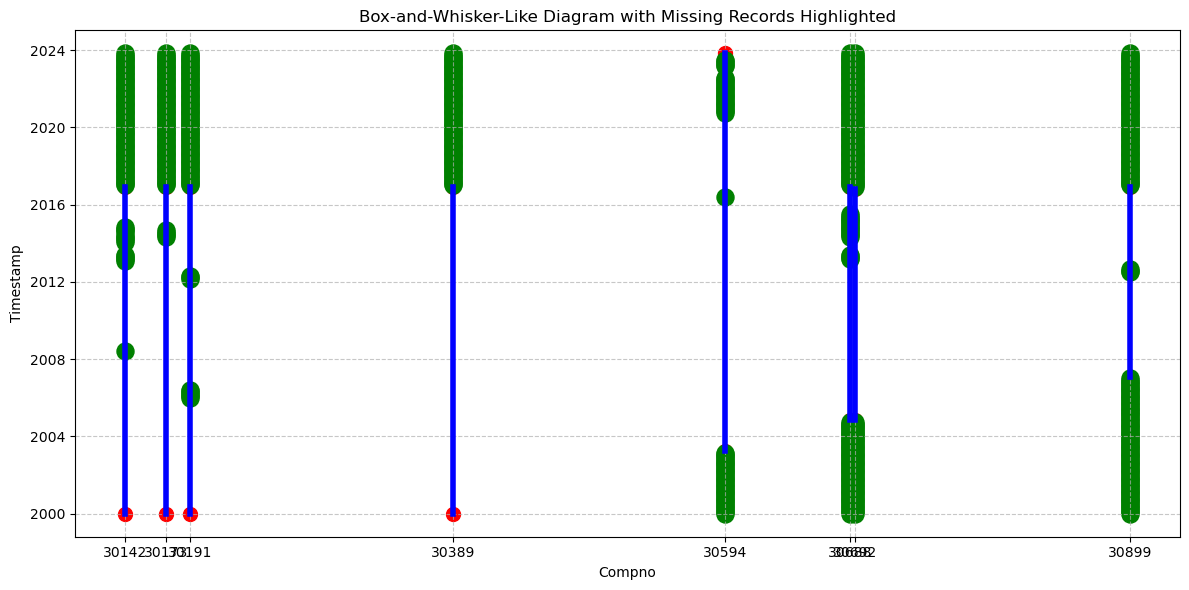

In [38]:
# Assuming attribute_df is your dataframe
# Convert TimeStamp to datetime
attribute_df['TimeStamp'] = pd.to_datetime(attribute_df['TimeStamp'])

# Create a complete range of timestamps for the dataset
all_timestamps = pd.date_range(start=attribute_df['TimeStamp'].min(), end=attribute_df['TimeStamp'].max(), freq='MS')

# Identify missing timestamps for each Compno
missing_timestamps = []

for compno in attribute_df['Compno'].unique():
    compno_timestamps = attribute_df[attribute_df['Compno'] == compno]['TimeStamp']
    missing = all_timestamps.difference(compno_timestamps)
    for timestamp in missing:
        missing_timestamps.append({'Compno': compno, 'TimeStamp': timestamp})

missing_df = pd.DataFrame(missing_timestamps)

# Group data to find the start and end timestamps for each Compno
start_end_df = attribute_df.groupby('Compno').agg(
    Start=('TimeStamp', 'min'),
    End=('TimeStamp', 'max')
).reset_index()

# Create the box-and-whisker-like diagram
plt.figure(figsize=(12, 6))

for index, row in start_end_df.iterrows():
    # Draw the whisker (line) for each Compno
    plt.plot([row['Compno'], row['Compno']], [row['Start'], row['End']], color='blue', linewidth=4)
    
    # Draw the "box" markers at the start and end points
    plt.scatter(row['Compno'], row['Start'], color='red', marker='o', s=100)
    plt.scatter(row['Compno'], row['End'], color='red', marker='o', s=100)

# Draw green dots for missing timestamps and make them thicker
if not missing_df.empty:
    for index, row in missing_df.iterrows():
        plt.scatter(row['Compno'], row['TimeStamp'], color='green', marker='o', s=150, label='Missing Record' if index == 0 else "")

# Set the x-axis to show only available Compno values
plt.xticks(ticks=start_end_df['Compno'], labels=start_end_df['Compno'])

# Enable horizontal and vertical grid lines
plt.grid(axis='both', linestyle='--', alpha=0.7)

# Format the graph
plt.title('Box-and-Whisker-Like Diagram with Missing Records Highlighted')
plt.xlabel('Compno')
plt.ylabel('Timestamp')
plt.tight_layout()
plt.show()


## Creating Edges

In [71]:
df1 = node_df[['ComputerNo', 'Latitude', 'Longitude', 'Altitude']]
df2 = df1

df1['key'] = 1
df2['key'] = 1

# Creating edges (Cross Join Nodes)
result = pd.merge(df1, df2, on='key').drop('key', axis=1)

result.rename(columns={'ComputerNo_x': 'CompNo1', 'Latitude_x': 'Lat1', 'Longitude_x': 'Long1', 'Altitude_x': 'Alt1', 'ComputerNo_y': 'CompNo2', 'Latitude_y': 'Lat2', 'Longitude_y': 'Long2', 'Altitude_y': 'Alt2'}, inplace=True)

In [72]:
def haversine(lat1, lon1, lat2, lon2, alt1, alt2):
    R = 6371  # Radius of the Earth in kilometers
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    horizontal_distance = R * c
    vertical_distance = alt2 - alt1
    distance = np.sqrt(horizontal_distance**2 + vertical_distance**2)
    return distance


result['distance_km'] = result.apply(lambda row: haversine(row['Lat1'], row['Long1'], row['Lat2'], row['Long2'], row['Alt1'], row['Alt2']), axis=1)

In [73]:
edges_df = result[result['distance_km'] != 0][['CompNo1', 'CompNo2', 'distance_km']]

In [78]:
# Get distinct rows
distinct_rows = edges_df.drop_duplicates()
distinct_rows.to_csv('edges_df.csv', index=False)

## Creating Graph TimeStamps

In [14]:
attribute_df.insert(1, 'TimeStamp', attribute_df.apply(lambda row: str(row['Year']).replace('.0', '') + "-" + str(row['Month']).replace('.0', ''), axis=1))

In [16]:
# Convert to Date format
attribute_df['TimeStamp'] = pd.to_datetime(attribute_df['TimeStamp'])

In [17]:
# Sorting dataset by TimeStamp
sorted_attributes = attribute_df.sort_values(by='TimeStamp')
attribute_df = sorted_attributes

In [20]:
attribute_df = attribute_df[attribute_df['Compno'] != 'nan']

## Get unique values from the 'Name' column

In [24]:
unique_values = attribute_df['Compno'].unique()

print(unique_values)

[30389 30142 30173 30191 30594 30688 30692 30899]


## Create Edge Attributes

In [25]:
attribute_df1 = attribute_df.merge(node_df, left_on=['Compno'], right_on=['ComputerNo']).drop(['ComputerNo'], axis=1)

In [26]:
attr = attribute_df[['TimeStamp', 'Compno']].sort_values(by='TimeStamp')
attr = attr.dropna(subset=['Compno'])

In [27]:
# Rename all columns by adding '_x' suffix 
attr_x = attribute_df.add_suffix('_x')
attr_y = attribute_df.add_suffix('_y')

In [28]:
# Perform cross join within each TimeStamp group 
cross_joined = attr.groupby('TimeStamp').apply(lambda x: x.assign(key=1).merge(x.assign(key=1), on='key')).drop('key', axis=1).reset_index(drop=True)
cross_joined[['TimeStamp']] = cross_joined[['TimeStamp_x']]
correct_attr = cross_joined.drop(['TimeStamp_x', 'TimeStamp_y'], axis=1)[['TimeStamp', 'Compno_x', 'Compno_y']]

In [29]:
# Merge DataFrames on 'Key1_df1' and 'Key2_df1' from df1 with 'Key1_df2' and 'Key2_df2' from df2 
merged_df = correct_attr.merge(attr_x, left_on=['TimeStamp', 'Compno_x'], right_on=['TimeStamp_x', 'Compno_x']).drop(['TimeStamp_x', 'Year_x', 'Month_x'], axis=1)
final_df_1 = merged_df.merge(attr_y, left_on=['TimeStamp', 'Compno_y'], right_on=['TimeStamp_y', 'Compno_y']).drop(['TimeStamp_y', 'Year_y', 'Month_y'], axis=1)

In [30]:
final_df = final_df_1.merge(edges_df, left_on=['Compno_x', 'Compno_y'], right_on=['CompNo1', 'CompNo2']).drop(['CompNo1', 'CompNo2'], axis=1)

## Sorting the data by TimeStamp

In [31]:
final_df = final_df.sort_values(by=['TimeStamp', 'Compno_x', 'Compno_y'])

In [44]:
final_df = pd.read_csv('final_df.csv')

## Check for Missing Edge Attributes

In [32]:
if final_df['distance_km'].isnull().any():
    print("There are missing values in the 'distance_km' column.")
    final_df = final_df.dropna(subset=['distance_km'])


## Feature Propagation

In [55]:
# Load the dataset
df = final_df

# Initialize dictionary to store graphs by timestamp
graphs_by_timestamp = {}

# Process data into graphs
for timestamp in df["TimeStamp"].unique():
    # Filter rows for the current timestamp
    sub_df = df[df["TimeStamp"] == timestamp]

    # Create graph for the timestamp
    G = nx.Graph()
    for _, row in sub_df.iterrows():
        # Add nodes and features
        G.add_node(row["Compno_x"], features=row[["AverageMaximumTemperature_x", 
                                                 "AverageMinimunTemperature_x", 
                                                 "AverageMaximumRelativeHumidity_x", 
                                                 "AverageMinimumRelativeHumidity_x", 
                                                 "TotalRainfall_x", 
                                                 "AverageTotalRadiation_x", 
                                                 "AverageWindSpeed_x", 
                                                 "AverageTotalRelativeEvaporation_x"]].values)
        G.add_node(row["Compno_y"], features=row[["AverageMaximumTemperature_y", 
                                                 "AverageMinimunTemperature_y", 
                                                 "AverageMaximumRelativeHumidity_y", 
                                                 "AverageMinimumRelativeHumidity_y", 
                                                 "TotalRainfall_y", 
                                                 "AverageTotalRadiation_y", 
                                                 "AverageWindSpeed_y", 
                                                 "AverageTotalRelativeEvaporation_y"]].values)
        # Add edge with weight
        G.add_edge(row["Compno_x"], row["Compno_y"], weight=row["distance_km"])
    
    # Store graph
    graphs_by_timestamp[timestamp] = G

# Feature propagation for missing nodes
def propagate_features(graph):
    for node in graph.nodes:
        if "features" not in graph.nodes[node]:
            # Aggregate features from neighbors
            neighbor_features = [
                graph.nodes[neighbor].get("features")
                for neighbor in graph.neighbors(node)
                if "features" in graph.nodes[neighbor]
            ]
            if neighbor_features:
                graph.nodes[node]["features"] = np.mean(neighbor_features, axis=0)
            else:
                graph.nodes[node]["features"] = np.zeros(8)  # Default to zero vector

# Apply feature propagation to all graphs
#for timestamp, G in graphs_by_timestamp.items():
#    propagate_features(G)

In [56]:
results_df = {}  # Initialize the results dictionary

for timestamp in df["TimeStamp"].unique():  # Iterate through unique timestamps
    new_df = graphs_by_timestamp[timestamp].nodes()  # Get nodes for the current timestamp
    results_df[timestamp] = new_df  # Add the data to the dictionary

In [57]:
# The list of labels (all possible unique values across the dictionary)
labels = [30142, 30173, 30191, 30389, 30688, 30692, 30899]

# Build the dataframe
data = []
for timestamp, nodes in results_df.items():
    row = {"TimeStamp": timestamp}
    for label in labels:
        row[label] = label in nodes
    data.append(row)

df = pd.DataFrame(data)

In [35]:
df = final_df

# Function to encode columns starting from 0 for each group
def encode_columns(group):
    le_x = LabelEncoder()
    le_y = LabelEncoder()
    group['Compno_x_encoded'] = le_x.fit_transform(group['Compno_x'])
    group['Compno_y_encoded'] = le_y.fit_transform(group['Compno_y'])
    return group

# Apply the encoding function to each group
df = df.groupby('TimeStamp').apply(encode_columns)

final_backup = final_df

final_df = df

final_df[['Compno_x', 'Compno_y']] = final_df[['Compno_x_encoded', 'Compno_y_encoded']]
final_df.drop(['Compno_x_encoded', 'Compno_y_encoded'], axis=1, inplace=True)

In [36]:
final_df = final_backup

,TimeStamp,Compno_x,Compno_y,AverageMaximumTemperature_x,AverageMinimunTemperature_x,AverageMaximumRelativeHumidity_x,AverageMinimumRelativeHumidity_x,TotalRainfall_x,AverageTotalRadiation_x,AverageWindSpeed_x,AverageTotalRelativeEvaporation_x,Target_x,AverageMaximumTemperature_y,AverageMinimunTemperature_y,AverageMaximumRelativeHumidity_y,AverageMinimumRelativeHumidity_y,TotalRainfall_y,AverageTotalRadiation_y,AverageWindSpeed_y,AverageTotalRelativeEvaporation_y,Target_y,distance_km
1339,2000-01-01,30142,30173,28.10,14.77,97.09,39.43,60.4,26.18,1.44,158.57,53.24750,32.89,18.73,82.92,23.31,39.0,29.91,1.96,209.35,54.75875,655.071776
1912,2000-01-01,30142,30191,28.10,14.77,97.09,39.43,60.4,26.18,1.44,158.57,53.24750,31.25,15.13,93.57,27.33,35.4,28.80,2.49,190.62,53.07375,335.864713
0,2000-01-01,30142,30389,28.10,14.77,97.09,39.43,60.4,26.18,1.44,158.57,53.24750,29.60,15.01,92.16,30.66,69.8,26.97,1.91,170.56,54.58375,220.023323
772,2000-01-01,30173,30142,32.89,18.73,82.92,23.31,39.0,29.91,1.96,209.35,54.75875,28.10,14.77,97.09,39.43,60.4,26.18,1.44,158.57,53.24750,655.071776
2092,2000-01-01,30173,30191,32.89,18.73,82.92,23.31,39.0,29.91,1.96,209.35,54.75875,31.25,15.13,93.57,27.33,35.4,28.80,2.49,190.62,53.07375,369.248018


In [58]:
# Convert 'Timestamp' column to datetime (if required)
df["TimeStamp"] = pd.to_datetime(df["TimeStamp"])

# Count the number of 0 values in each row
rows_with_two_or_more_zeros = df[df.eq(False).sum(axis=1) > 2]

# Select the timestamps
timestamps = rows_with_two_or_more_zeros["TimeStamp"]

print('Number of Timestamps: ' , df['TimeStamp'].nunique())
print('Number of Timestamps: ' , len(timestamps))
print('Remaining Graphs: ' , (int(df['TimeStamp'].nunique()) - int(len(timestamps))))
#print(timestamps)

Number of Timestamps:  204
Number of Timestamps:  62
Remaining Graphs:  142


In [54]:
# Drop rows where 'Timestamp' is in the list
df = df[~df["TimeStamp"].isin(timestamps)]

## Min-Max Scaling

In [80]:
scaler = MinMaxScaler()
final_df[['Target_x', 'Target_y']] = scaler.fit_transform(final_df[['Target_x', 'Target_y']])

In [81]:
# Check for null values
#print(final_df.isnull())       # Shows True/False for each element
print(final_df.isnull().any()) # Shows if any column has null values
#print(final_df.isnull().sum()) 

TimeStamp                            False
Compno_x                             False
Compno_y                             False
distance_km                          False
AverageMaximumTemperature_x          False
AverageMinimunTemperature_x          False
AverageMaximumRelativeHumidity_x     False
AverageMinimumRelativeHumidity_x     False
TotalRainfall_x                      False
AverageTotalRadiation_x              False
AverageWindSpeed_x                   False
AverageTotalRelativeEvaporation_x    False
Target_x                             False
AverageMaximumTemperature_y          False
AverageMinimunTemperature_y          False
AverageMaximumRelativeHumidity_y     False
AverageMinimumRelativeHumidity_y     False
TotalRainfall_y                      False
AverageTotalRadiation_y              False
AverageWindSpeed_y                   False
AverageTotalRelativeEvaporation_y    False
Target_y                             False
dtype: bool


In [82]:
null_rows = final_df[final_df.isnull().any(axis=1)]
null_rows.head(5)

,TimeStamp,Compno_x,Compno_y,distance_km,AverageMaximumTemperature_x,AverageMinimunTemperature_x,AverageMaximumRelativeHumidity_x,AverageMinimumRelativeHumidity_x,TotalRainfall_x,AverageTotalRadiation_x,AverageWindSpeed_x,AverageTotalRelativeEvaporation_x,Target_x,AverageMaximumTemperature_y,AverageMinimunTemperature_y,AverageMaximumRelativeHumidity_y,AverageMinimumRelativeHumidity_y,TotalRainfall_y,AverageTotalRadiation_y,AverageWindSpeed_y,AverageTotalRelativeEvaporation_y,Target_y


# Data Exploration

In [37]:
node_df.head(20)

,ComputerNo,StationName,Latitude,Longitude,Altitude
0,30688,VANWYKSVLEI,-30.408260,21.855016,999
1,30142,JANKEMPDORP; VAALHARTS,-27.957700,24.839940,1165
2,30173,KAKAMAS; KROMHOUT BOERDERY,-28.786900,20.655190,662
3,30191,PRIESKA; BLAAUKRANS,-29.525310,22.972690,943
4,30389,LUCKHOF; BLESKOP,-29.879560,24.582830,1119
5,20272,BRANDVLEI,-30.466667,20.483334,914
6,30692,BRANDVLEI,-30.371820,20.509860,929
7,20197,VAN WYKSVLEI,-30.350000,21.816668,962
8,30688,VANWYKSVLEI,-30.408260,21.855016,999
9,30899,OLIFANSTHOEK: MURRAY,-27.910130,22.863860,1222


In [38]:
attribute_df.head(5)

,Compno,TimeStamp,Year,Month,AverageMaximumTemperature,AverageMinimunTemperature,AverageMaximumRelativeHumidity,AverageMinimumRelativeHumidity,TotalRainfall,AverageTotalRadiation,AverageWindSpeed,AverageTotalRelativeEvaporation,Target
0,30389,2000-01-01,2000,1,29.60,15.01,92.16,30.66,69.8,26.97,1.91,170.56,54.58375
0,30142,2000-01-01,2000,1,28.10,14.77,97.09,39.43,60.4,26.18,1.44,158.57,53.24750
0,30173,2000-01-01,2000,1,32.89,18.73,82.92,23.31,39.0,29.91,1.96,209.35,54.75875
0,30191,2000-01-01,2000,1,31.25,15.13,93.57,27.33,35.4,28.80,2.49,190.62,53.07375
1,30173,2000-02-01,2000,2,35.18,19.82,79.17,25.19,44.4,26.89,1.86,180.21,51.59000


In [39]:
edges_df.head(5)

,CompNo1,CompNo2,distance_km
1,30688,30142,430.985911
2,30688,30173,399.409471
3,30688,30191,156.097747
4,30688,30389,294.369313
5,30688,20272,156.716859


In [40]:
grouped = attribute_df[['Compno', 'TimeStamp']]

C:\Users\ZAMA\AppData\Local\Temp\ipykernel_21804\834294326.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  grouped['year_month'] = grouped['TimeStamp'].dt.to_period('M')


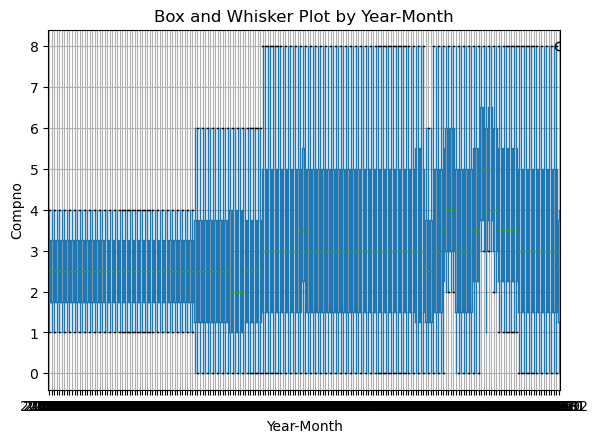

In [37]:
# Extract year and month 
grouped['year_month'] = grouped['TimeStamp'].dt.to_period('M') 

# Create a box plot 
grouped.boxplot(column='Compno', by='year_month')

plt.title('Box and Whisker Plot by Year-Month') 
plt.suptitle('') # Suppress the default title 
plt.xlabel('Year-Month') 
plt.ylabel('Compno') 
plt.show()

In [34]:
grouped = attribute_df[['Compno', 'TimeStamp']]

plt.figure(figsize=(30, 20))
grouped.boxplot(by=['Compno'], color='blue')
plt.title("Dataset year range")
plt.ylabel("TimeStamp")
plt.xlabel("Data Station Number")
plt.xticks(rotation=45) # Rotate x-axis labels for better readability
plt.show()

ValueError: Number of columns must be a positive integer, not 0

<Figure size 3000x2000 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [ ]:
G = nx.from_pandas_edgelist(edges_df, 'CompNo1', 'CompNo2', ['distance_km'])

In [ ]:
plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G)  # positions for all nodes
nx.draw(G, pos, with_labels=True, node_size=700, node_color='skyblue', font_size=15, font_color='black', font_weight='bold')
labels = nx.get_edge_attributes(G, 'distance_km')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)
plt.title('Graph with Nodes and Connections')
plt.show()

In [ ]:
node_colors = ['skyblue' if node != 1 else 'orange' for node in G.nodes()]

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G)  # positions for all nodes
nx.draw(G, pos, with_labels=True, node_size=700, node_color=node_colors, font_size=15, font_color='black', font_weight='bold')
labels = nx.get_edge_attributes(G, 'Weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)
plt.title('Graph with Nodes and Connections')
plt.show()

In [ ]:
graph_df = edges_df
graph_df.loc[len(graph_df)] = [10, 0, 0]

In [ ]:
G = nx.from_pandas_edgelist(graph_df, 'CompNo1', 'CompNo2', ['distance_km'])

node_colors = ['skyblue' if node != 10 else 'orange' for node in G.nodes()]

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G)  # positions for all nodes
nx.draw(G, pos, with_labels=True, node_size=700, node_color=node_colors, font_size=15, font_color='black', font_weight='bold')
labels = nx.get_edge_attributes(G, 'Weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)
plt.title('Graph with Nodes and Connections')
plt.show()

In [ ]:
# Assuming final_df is your dataset
def draw_graphs(df, start_time, end_time):
    # Convert the TimeStamp column to datetime format
    df['TimeStamp'] = pd.to_datetime(df['TimeStamp'])
    # Filter the dataset for the specified time period
    filtered_df = df[(df['TimeStamp'] >= start_time) & (df['TimeStamp'] <= end_time)]
    
    timestamps = filtered_df['TimeStamp'].unique()
    for timestamp in timestamps:
        sub_df = filtered_df[filtered_df['TimeStamp'] == timestamp]
        G = nx.Graph()
        
        # Add edges and node features
        for _, row in sub_df.iterrows():
            G.add_edge(row['Compno_x'], row['Compno_y'], weight=row['distance_km'])
            G.nodes[row['Compno_x']].update({col: row[col] for col in row.index if col.endswith('_x')})
            G.nodes[row['Compno_y']].update({col: row[col] for col in row.index if col.endswith('_y')})
        
        pos = nx.spring_layout(G)  # You can choose other layouts like kamada_kawai_layout, spectral_layout, etc.
        edge_weights = nx.get_edge_attributes(G, 'weight')
        
        plt.figure(figsize=(10, 7))
        ax = plt.gca()  # Get the current axes object
        nx.draw(G, pos, with_labels=True, node_size=700, node_color='lightblue', ax=ax)
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_weights, ax=ax)
        
        # Convert numpy.datetime64 to pandas.Timestamp for formatting
        timestamp_str = pd.Timestamp(timestamp).strftime('%Y-%m-%d')
        plt.title(f"Graph for Timestamp: {timestamp_str}")
        plt.show()

# Call the function to draw graphs for a specific time period
# Example time period: January 1, 2000 to March 1, 2000
start_time = '2009-01-01'
end_time = '2009-03-01'
draw_graphs(final_df, start_time, end_time)

In [ ]:
final_df.head(10)

In [ ]:
# Function to check for strings in DataFrame
def check_for_strings(df):
    string_df = df.applymap(lambda x: isinstance(x, str)) 
    return string_df

# Function to check if there is a True value anywhere in the DataFrame 
def check_for_true(df):
    return df.applymap(lambda x: isinstance(x, str)).any().any()

# Check for strings
string_check = check_for_strings(final_df)

has_true = check_for_true(string_check) 
print(has_true)


In [41]:
# Saving clean dataset to disk
final_df.to_csv('final_df.csv', index=False)

# Creating Temporal Graph Datasets

## Fixing the Data

In [5]:
corrected_df = pd.read_csv('corrected_df.csv')

# Convert to datetime format
corrected_df['TimeStamp'] = pd.to_datetime(corrected_df['TimeStamp'])

# Convert to Unix timestamp (seconds since epoch)
corrected_df['TimeStamp'] = corrected_df['TimeStamp'].apply(lambda x: x.timestamp())

# Columns to exclude
exclude_cols = ['TimeStamp', 'Compno_x', 'Compno_y', 'Target_x', 'Target_y']

# Select columns for scaling
cols_to_scale = corrected_df.columns.difference(exclude_cols)  # Find columns not in exclude list

# Apply Min-Max Scaling
scaler = MinMaxScaler()
corrected_df[cols_to_scale] = scaler.fit_transform(corrected_df[cols_to_scale])

# Create five quantile-based categories
corrected_df['Target_x'] = pd.qcut(corrected_df['Target_x'], q=5, labels=[0, 1, 2, 3, 4])
corrected_df['Target_y'] = pd.qcut(corrected_df['Target_y'], q=5, labels=[0, 1, 2, 3, 4])

corrected_df.to_csv('corrected1_df.csv', index=False)

corrected_df.head(10)

,TimeStamp,Compno_x,Compno_y,distance_km,AverageMaximumTemperature_x,AverageMinimunTemperature_x,AverageMaximumRelativeHumidity_x,AverageMinimumRelativeHumidity_x,TotalRainfall_x,AverageTotalRadiation_x,AverageWindSpeed_x,AverageTotalRelativeEvaporation_x,Target_x,AverageMaximumTemperature_y,AverageMinimunTemperature_y,AverageMaximumRelativeHumidity_y,AverageMinimumRelativeHumidity_y,TotalRainfall_y,AverageTotalRadiation_y,AverageWindSpeed_y,AverageTotalRelativeEvaporation_y,Target_y
0,1.099267e+09,0,1,0.647973,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.474964,0.052439,0.794900,0.322783,0.176807,0.673114,0.066119,0.662945,4
1,1.099267e+09,0,2,0.598369,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.493457,0.056954,0.637158,0.301217,0.008590,0.839182,0.056184,0.754691,3
2,1.099267e+09,0,3,0.216139,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.503272,0.053673,0.678780,0.217043,0.019327,0.846366,0.070915,0.848778,3
3,1.099267e+09,0,4,0.433356,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.482077,0.053085,0.775956,0.286261,0.041518,0.851893,0.067146,0.801504,4
4,1.099267e+09,0,5,0.201603,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.466287,0.053506,0.567760,0.226435,0.008590,0.797458,0.119904,0.514293,2
5,1.099267e+09,0,6,0.551284,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.483452,0.054112,0.650137,0.258812,0.047721,0.799668,0.078908,0.688749,3
6,1.099267e+09,0,7,0.217112,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.483452,0.054112,0.650137,0.258812,0.047721,0.799668,0.078908,0.688749,3
7,1.099267e+09,0,8,0.030210,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.483452,0.054112,0.650137,0.258812,0.047721,0.799668,0.078908,0.688749,3
8,1.099267e+09,1,0,0.647973,0.474964,0.474964,0.794900,0.322783,0.176807,0.673114,0.066119,0.662945,4,0.480654,0.055015,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2
9,1.099267e+09,1,2,1.000000,0.474964,0.474964,0.794900,0.322783,0.176807,0.673114,0.066119,0.662945,4,0.493457,0.056954,0.637158,0.301217,0.008590,0.839182,0.056184,0.754691,3


## Reading Saved Dataset

In [5]:
#final_df = pd.read_csv('corrected_df.csv')
final_df = pd.read_csv('corrected1_df.csv')

In [6]:
final_df.head(10)

,TimeStamp,Compno_x,Compno_y,distance_km,AverageMaximumTemperature_x,AverageMinimunTemperature_x,AverageMaximumRelativeHumidity_x,AverageMinimumRelativeHumidity_x,TotalRainfall_x,AverageTotalRadiation_x,AverageWindSpeed_x,AverageTotalRelativeEvaporation_x,Target_x,AverageMaximumTemperature_y,AverageMinimunTemperature_y,AverageMaximumRelativeHumidity_y,AverageMinimumRelativeHumidity_y,TotalRainfall_y,AverageTotalRadiation_y,AverageWindSpeed_y,AverageTotalRelativeEvaporation_y,Target_y
0,1.099267e+09,0,1,0.647973,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.474964,0.052439,0.794900,0.322783,0.176807,0.673114,0.066119,0.662945,4
1,1.099267e+09,0,2,0.598369,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.493457,0.056954,0.637158,0.301217,0.008590,0.839182,0.056184,0.754691,3
2,1.099267e+09,0,3,0.216139,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.503272,0.053673,0.678780,0.217043,0.019327,0.846366,0.070915,0.848778,3
3,1.099267e+09,0,4,0.433356,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.482077,0.053085,0.775956,0.286261,0.041518,0.851893,0.067146,0.801504,4
4,1.099267e+09,0,5,0.201603,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.466287,0.053506,0.567760,0.226435,0.008590,0.797458,0.119904,0.514293,2
5,1.099267e+09,0,6,0.551284,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.483452,0.054112,0.650137,0.258812,0.047721,0.799668,0.078908,0.688749,3
6,1.099267e+09,0,7,0.217112,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.483452,0.054112,0.650137,0.258812,0.047721,0.799668,0.078908,0.688749,3
7,1.099267e+09,0,8,0.030210,0.480654,0.480654,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2,0.483452,0.054112,0.650137,0.258812,0.047721,0.799668,0.078908,0.688749,3
8,1.099267e+09,1,0,0.647973,0.474964,0.474964,0.794900,0.322783,0.176807,0.673114,0.066119,0.662945,4,0.480654,0.055015,0.446266,0.199130,0.031496,0.789997,0.093183,0.550286,2
9,1.099267e+09,1,2,1.000000,0.474964,0.474964,0.794900,0.322783,0.176807,0.673114,0.066119,0.662945,4,0.493457,0.056954,0.637158,0.301217,0.008590,0.839182,0.056184,0.754691,3


## Create Conversion Functions

In [7]:
def convert_timestamps_to_float_tensor(timestamps):
    new_timestamps = []
    for timestamp in timestamps:
        if isinstance(timestamp, torch.Tensor):
            new_timestamps.append(timestamp.float())
        elif isinstance(timestamp, (list, tuple)):
            new_timestamps.append(torch.FloatTensor(timestamp))
        elif isinstance(timestamp, str):
            try:
                # Convert timestamp string to Unix time
                dt_object = datetime.strptime(timestamp, "%Y-%m-%d")
                unix_timestamp = dt_object.timestamp()
                new_timestamps.append(torch.FloatTensor([unix_timestamp]))
            except ValueError:
                raise ValueError(f"Invalid timestamp format: {timestamp}")
        else:
            raise ValueError(f"Unsupported timestamp type: {type(timestamp)}")
    
    return new_timestamps

def convert_targets_to_float_tensor(targets):
    new_targets = []
    for target in targets:
        if isinstance(target, torch.Tensor):
            new_targets.append(target.float())
        elif isinstance(target, (list, tuple)):
            new_targets.append(torch.FloatTensor(target))
        elif isinstance(target, str):
            # Convert string target to float tensor; assuming it is comma-separated numbers
            float_target = torch.FloatTensor([float(x) for x in target.split(',') if x.replace('.', '', 1).isdigit()])
            new_targets.append(float_target)
        else:
            raise ValueError(f"Unsupported target type: {type(target)}")
    return new_targets

def convert_batches_to_long_tensor(batches):
    new_batches = []
    for batch in batches:
        if isinstance(batch, torch.Tensor):
            new_batches.append(batch.long())
        elif isinstance(batch, (list, tuple)):
            new_batches.append(torch.LongTensor(batch))
        elif isinstance(batch, str):
            # Convert string batch to long tensor; assuming it is comma-separated integers
            long_batch = torch.LongTensor([int(x) for x in batch.split(',') if x.isdigit()])
            new_batches.append(long_batch)
        else:
            raise ValueError(f"Unsupported batch type: {type(batch)}")
    return new_batches

def convert_edge_weights_to_float_tensor(edge_weights):
    new_edge_weights = []
    for weight in edge_weights:
        if isinstance(weight, torch.Tensor):
            new_edge_weights.append(weight.float())
        elif isinstance(weight, (list, tuple)):
            new_edge_weights.append(torch.FloatTensor(weight))
        elif isinstance(weight, str):
            # Convert string edge weight to float tensor; assuming it is comma-separated numbers
            float_weight = torch.FloatTensor([float(x) for x in weight.split(',') if x.replace('.', '', 1).isdigit()])
            new_edge_weights.append(float_weight)
        else:
            raise ValueError(f"Unsupported edge weight type: {type(weight)}")
    return new_edge_weights

def convert_features_to_float_tensor(features):
    new_features = []
    for feature in features:
        try:
            if isinstance(feature, torch.Tensor):
                new_features.append(feature.float())
            elif isinstance(feature, (list, tuple)):
                new_features.append(torch.FloatTensor(feature))
            elif isinstance(feature, str):
                # Convert string feature to float tensor; assuming it is comma-separated numbers
                float_feature = torch.FloatTensor([float(x) for x in feature.split(',') if x.replace('.', '', 1).isdigit()])
                new_features.append(float_feature)
            else:
                new_features.append(torch.FloatTensor(feature.to_numpy()))
        except ValueError:
            print(f"Warning: Skipping non-numeric feature: {feature}")
    return new_features

def convert_edges_to_long_tensor(edge_indices):
    new_edge_indices = []
    for edge in edge_indices:
        if isinstance(edge, torch.Tensor):
            new_edge_indices.append(edge.long())
        elif isinstance(edge, (list, tuple)):
            new_edge_indices.append(torch.LongTensor(edge))
        elif isinstance(edge, str):
            # Convert string edge index to long tensor; assuming it is comma-separated integers
            long_edge = torch.LongTensor([int(x) for x in edge.split(',') if x.isdigit()])
            new_edge_indices.append(long_edge)
        else:
            raise ValueError(f"Unsupported edge index type: {type(edge)}")
    return new_edge_indices

## Building Graphs

In [8]:
# Assuming 'final_df' has a 'timestamp' column
timestamps = final_df['TimeStamp'].unique()

# Initialize lists to store data for each timestamp
edge_indices_list = []
edge_weights_list = []
node_features_list = []
targets_list = []
all_batches = []
timestamps_list = []

for timestamp in timestamps:
    df_timestamp = final_df[final_df['TimeStamp'] == timestamp]
    
    # Convert timestamp string to numerical (Unix timestamp)
    if isinstance(timestamp, str):
        try:
            dt_object = datetime.strptime(timestamp, "%Y-%m-%d")
            timestamp_numeric = dt_object.timestamp()
        except ValueError:
            raise ValueError(f"Invalid timestamp format: {timestamp}")
    else:
        timestamp_numeric = float(timestamp)  # If it's already a number
    
    # Node features
    node_features = df_timestamp[['Compno_x', 'AverageMaximumTemperature_x', 'AverageMinimunTemperature_x', 
                                  'AverageMaximumRelativeHumidity_x', 'AverageMinimumRelativeHumidity_x', 
                                  'TotalRainfall_x', 'AverageTotalRadiation_x', 'AverageWindSpeed_x', 
                                  'AverageTotalRelativeEvaporation_x']].drop_duplicates()
    node_features = node_features.sort_values(by='Compno_x')
    x = torch.tensor(node_features[['AverageMaximumTemperature_x', 'AverageMinimunTemperature_x', 
                                    'AverageMaximumRelativeHumidity_x', 'AverageMinimumRelativeHumidity_x', 
                                    'TotalRainfall_x', 'AverageTotalRadiation_x', 'AverageWindSpeed_x', 
                                    'AverageTotalRelativeEvaporation_x']].values, dtype=torch.float)
    
    # Edge indices
    edge_indices = torch.tensor(df_timestamp[['Compno_x', 'Compno_y']].values.T, dtype=torch.long)
    
    # Edge weights
    edge_weights = torch.tensor(df_timestamp['distance_km'].values, dtype=torch.float)
    
    #edge_indices = [torch.randint(0, n_nodes, (2, n_edges), dtype=torch.long) for _ in df_timestamps] 
    #edge_weights = [torch.rand(n_edges) for _ in timestamps]
    
    # Targets
    targets = df_timestamp[['Compno_x', 'Target_x']].drop_duplicates()['Target_x'].values
    targets_np = np.array(targets, dtype=np.float)
    targets_tensor = torch.tensor(targets_np, dtype=torch.float)
    
    # Generate batches (assuming each timestamp is a separate batch)
    batch = torch.tensor([i for i in range(len(df_timestamp))], dtype=torch.long)
    
    snapshot_timestamp = torch.FloatTensor([timestamp])
    
    # Append to lists
    node_features_list.append(x)
    edge_indices_list.append(edge_indices)
    edge_weights_list.append(edge_weights)
    targets_list.append(targets_tensor)
    all_batches.append(batch)
    timestamps_list.append(snapshot_timestamp)   # Keep the timestamp
    
# Ensure the length consistency across all lists
assert len(edge_indices_list) == len(edge_weights_list) == len(node_features_list) == len(targets_list) == len(all_batches) == len(timestamps_list), "Temporal dimension inconsistency."


C:\Users\ZAMA\AppData\Local\Temp\ipykernel_18172\1174984308.py:47: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  targets_np = np.array(targets, dtype=np.float)


In [9]:
# Create a DynamicGraphTemporalSignal object
dataset = DynamicGraphTemporalSignalBatch(
    edge_indices=edge_indices_list,
    edge_weights=edge_weights_list,
    features=node_features_list,
    targets=targets_list,
    batches=all_batches,
    timestamps=timestamps_list
)

In [10]:
# Example usage
i = 1
print("DynamicGraphTemporalSignal created with the following properties:")
print(f"Number of snapshots\t: {dataset.snapshot_count}")
print(f"Timestamp: \t: {str(dataset.timestamps[i])}")
print(f"Snapshot {i} Features\t: \n{dataset.features[i]}")
print(f"Snapshot {i} Edges\t: \n{dataset.edge_indices[i]}")
print(f"Snapshot {i} Edge Weights\t: \n{dataset.edge_weights[i]}")
print(f"Snapshot {i} Targets\t\t: \n{dataset.targets[i]}")

DynamicGraphTemporalSignal created with the following properties:
Number of snapshots	: 142
Timestamp: 	: tensor([1.1019e+09])
Snapshot 1 Features	: 
tensor([[5.0313e-01, 5.0313e-01, 4.8597e-01, 1.7722e-01, 7.1582e-04, 8.5079e-01,
         1.0620e-01, 9.3615e-01],
        [4.5804e-01, 4.5804e-01, 8.5756e-01, 5.1896e-01, 4.7351e-01, 7.0848e-01,
         8.0507e-02, 6.6839e-01],
        [5.0199e-01, 5.0199e-01, 6.7832e-01, 2.6852e-01, 3.2928e-02, 9.4833e-01,
         7.0915e-02, 8.8765e-01],
        [5.1394e-01, 5.1394e-01, 7.1858e-01, 2.2296e-01, 1.5676e-01, 9.4860e-01,
         8.2220e-02, 9.7187e-01],
        [4.8293e-01, 4.8293e-01, 7.8215e-01, 3.4174e-01, 1.4817e-01, 9.0522e-01,
         8.0507e-02, 8.5860e-01],
        [4.8592e-01, 4.8592e-01, 6.0073e-01, 2.0435e-01, 1.4316e-02, 8.5631e-01,
         1.2915e-01, 9.3016e-01],
        [4.9099e-01, 4.9099e-01, 6.8722e-01, 2.8896e-01, 1.3774e-01, 8.6962e-01,
         9.1584e-02, 8.7547e-01],
        [4.9099e-01, 4.9099e-01, 6.8722e-01, 

# Preparing the Data Loader

In [11]:
# Custom DataLoader for DynamicGraphTemporalSignalBatch
class TemporalDataLoader:
    def __init__(self, dataset):
        self.dataset = dataset
        self.snapshot_count = dataset.snapshot_count

    def __len__(self):
        return self.snapshot_count

    def __iter__(self):
        for i in range(len(self)):
            yield self.dataset[i]

# Assuming 'dataset' is a DynamicGraphTemporalSignalBatch object
# Split dataset into training and test sets
train_dataset, test_dataset = temporal_signal_split(dataset, train_ratio=0.8)

# Create a custom data loader
train_loader = TemporalDataLoader(train_dataset)
test_loader = TemporalDataLoader(test_dataset)

print(train_loader)

In [12]:
tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_idx, test_idx) in enumerate(tscv.split(train_dataset.timestamps)):
    train_subset = [dataset[i] for i in train_idx]
    test_subset = [dataset[i] for i in test_idx]
    
    #train_loader = DataLoader(train_subset, batch_size=32, shuffle=False)  # No shuffle for time series
    test_loader = DataLoader(test_subset, batch_size=32)

    print(train_loader)
    
    #train_loss, train_accuracy = train(train_loader)
    #test_loss, test_accuracy = test(test_loader)
    
    #print(f"Fold {fold + 1}: Test Accuracy {test_accuracy:.4f}")


# Define the TSGNN Model

In [33]:
class TemporalSpatialNodeClassifier(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes):
        super(TemporalSpatialNodeClassifier, self).__init__()

        # Updated to accept timestamp as an extra input feature
        self.input_fc = nn.Linear(in_channels + 1, hidden_channels)

        self.spatial_conv1 = GCNConv(hidden_channels, hidden_channels)
        self.spatial_conv2 = GCNConv(hidden_channels, hidden_channels)

        self.layer_norm_spatial1 = nn.LayerNorm(hidden_channels)
        self.layer_norm_spatial2 = nn.LayerNorm(hidden_channels)

        self.dropout1 = nn.Dropout(0.3)
        self.dropout2 = nn.Dropout(0.3)

        self.temporal_fc1 = nn.Linear(hidden_channels, hidden_channels)
        self.temporal_fc2 = nn.Linear(hidden_channels, hidden_channels)

        self.layer_norm_temporal1 = nn.LayerNorm(hidden_channels)
        self.layer_norm_temporal2 = nn.LayerNorm(hidden_channels)

        self.classifier = nn.Linear(hidden_channels, num_classes)

    def forward(self, x, edge_index, edge_weight, timestamp, batch=None):
        
        # Concatenate timestamp to each node feature vector
        timestamp = timestamp.repeat(x.size(0), 1)  # Expands [1] → [num_nodes, 1]
        x = torch.cat([x, timestamp], dim=1)

        x = F.relu(self.input_fc(x))

        x = F.relu(self.layer_norm_spatial1(self.spatial_conv1(x, edge_index, edge_weight)))
        x = self.dropout1(x)
        x = F.relu(self.layer_norm_spatial2(self.spatial_conv2(x, edge_index, edge_weight)))

        x = F.relu(self.layer_norm_temporal1(self.temporal_fc1(x)))
        x = self.dropout2(x)
        x = F.relu(self.layer_norm_temporal2(self.temporal_fc2(x)))

        if batch is not None:
            x = global_mean_pool(x, batch)

        out = self.classifier(x)
        return F.log_softmax(out, dim=1)

# Training Model

In [42]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

node_features_size=8
hidden_channels=8
num_classes=5

# Example model definition - Ensure this is the correct model
model = TemporalSpatialNodeClassifier(node_features_size, hidden_channels, num_classes)
print(model)


# optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
# criterion = torch.nn.MSELoss()

optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=5e-4)
criterion = nn.CrossEntropyLoss()

TemporalSpatialNodeClassifier(
  (input_fc): Linear(in_features=9, out_features=8, bias=True)
  (spatial_conv1): GCNConv(8, 8)
  (spatial_conv2): GCNConv(8, 8)
  (layer_norm_spatial1): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
  (layer_norm_spatial2): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
  (dropout1): Dropout(p=0.3, inplace=False)
  (dropout2): Dropout(p=0.3, inplace=False)
  (temporal_fc1): Linear(in_features=8, out_features=8, bias=True)
  (temporal_fc2): Linear(in_features=8, out_features=8, bias=True)
  (layer_norm_temporal1): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
  (layer_norm_temporal2): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
  (classifier): Linear(in_features=8, out_features=5, bias=True)
)


In [35]:
def train(dynamic_graph_batch):
    model.train()
    optimizer.zero_grad()

    # Ensure batch indices do not exceed the number of nodes in features
    #timestamps_tensor = torch.FloatTensor(dynamic_graph_batch.timestamps).unsqueeze(1).to(device)

    features, edge_indices, edge_weights, targets, timestamps = (
        dynamic_graph_batch.features,
        dynamic_graph_batch.edge_indices,
        dynamic_graph_batch.edge_weights,
        dynamic_graph_batch.targets,
        dynamic_graph_batch.timestamps
    )

    out = model(features[1], edge_indices[1], edge_weights[1], timestamps[1])

    targets_long = targets[1].clone().to(torch.long)
    loss = criterion(out, targets_long)  # Correct dtype

    loss.backward()
    optimizer.step()
    
    return loss.item()

In [36]:
def test(dynamic_graph_batch):
    model.eval()  # Set model to evaluation mode
    test_loss = 0

    with torch.no_grad():  # Disable gradient computation for efficiency
        features, edge_indices, edge_weights, targets, timestamps = (
            dynamic_graph_batch.features,
            dynamic_graph_batch.edge_indices,
            dynamic_graph_batch.edge_weights,
            dynamic_graph_batch.targets,
            dynamic_graph_batch.timestamps
        )

        out = model(features[1], edge_indices[1], edge_weights[1], timestamps[1])
        
    return out

In [37]:
PerformanceMatrices = pd.DataFrame(columns=['Epoch', 'Train Loss', 'Test Loss', 'Test Accuracy', 'Train F1', 'Test F1', 'Train Precision', 'Test Precision'])

for epoch in range(1, 300):
    train_loss = 0
    test_loss = 0
    correct_predictions = 0
    total_samples = 0
    
    # ---- Training Phase ----
    for dynamic_graph_batch in train_loader:
        # Process input features
        features, edge_indices, edge_weights, targets, batch, timestamps = dynamic_graph_batch

        # Convert inputs to correct tensor formats
        edge_indices = convert_edges_to_long_tensor(edge_indices)
        edge_weights = convert_edge_weights_to_float_tensor(edge_weights)
        features = convert_features_to_float_tensor(features)
        targets = convert_targets_to_float_tensor(targets)
        
        dynamic_graph_batch = DynamicGraphTemporalSignalBatch(
            edge_indices=edge_indices,
            edge_weights=edge_weights,
            features=features,
            targets=targets,
            batches=batch,
            timestamps=timestamps
        )

        train_loss += train(dynamic_graph_batch)
    
    # ---- Testing Phase ----
    test_loss = 0
    model.eval()
    with torch.no_grad():
        for dynamic_graph in test_loader:
            # Process input features
            features, edge_indices, edge_weights, targets, batch, timestamps = dynamic_graph

            # Convert inputs to correct tensor formats
            edge_indices = convert_edges_to_long_tensor(edge_indices)
            edge_weights = convert_edge_weights_to_float_tensor(edge_weights)
            features = convert_features_to_float_tensor(features)
            targets = convert_targets_to_float_tensor(targets)

            dynamic_graph_batch = DynamicGraphTemporalSignalBatch(
                edge_indices=edge_indices,
                edge_weights=edge_weights,
                features=features,
                targets=targets,
                batches=batch,
                timestamps=timestamps
            )
            
            # Compute predictions
            out = test(dynamic_graph_batch)  # Call the test function
            predictions = out.argmax(dim=1)
                
            # Compute test loss
            targets = targets[1].clone().to(torch.long)
            loss = criterion(out, targets)  # Correct dtype
            test_loss += loss.item()  # Accumulate loss
            
            # Count correct predictions
            correct_predictions += (predictions == targets).sum().item()
            total_samples += targets.size(0)
            
    # Compute test accuracy
    test_accuracy = ((correct_predictions / total_samples) * 100) if total_samples > 0 else 0

    # Print progress
    print(f"Epoch {epoch}: Train Loss = {train_loss:.4f}, Test Loss = {test_loss:.4f}, Test Accuracy = {test_accuracy:.4f}")
        
    # Append results to DataFrame
    PerformanceMatrices.loc[len(PerformanceMatrices)] = [epoch, train_loss, test_loss, test_accuracy, None, None, None, None] 

RuntimeError: mat1 and mat2 shapes cannot be multiplied (9x9 and 26x8)

In [ ]:
# Save the entire model
torch.save(model, 'temporal_spatial_classifier.pth')

# Save just the model state dictionary
torch.save(model.state_dict(), 'temporal_spatial_classifier_state.pth')

# Evaluate the Model

In [20]:
# Load entire model
model = torch.load('temporal_spatial_classifier.pth')
model.eval()  # Set to evaluation mode

# Load state dictionary
model = TemporalSpatialNodeClassifier(node_features_size, hidden_channels, num_classes)  # Ensure model architecture matches
model.load_state_dict(torch.load('temporal_spatial_classifier_state.pth'))
model.eval()

TemporalSpatialNodeClassifier(
  (spatial_conv1): GCNConv(8, 8)
  (spatial_conv2): GCNConv(8, 8)
  (layer_norm_spatial1): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
  (layer_norm_spatial2): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
  (dropout1): Dropout(p=0.3, inplace=False)
  (dropout2): Dropout(p=0.3, inplace=False)
  (temporal_fc1): Linear(in_features=8, out_features=8, bias=True)
  (temporal_fc2): Linear(in_features=8, out_features=8, bias=True)
  (layer_norm_temporal1): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
  (layer_norm_temporal2): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
  (classifier): Linear(in_features=8, out_features=5, bias=True)
)

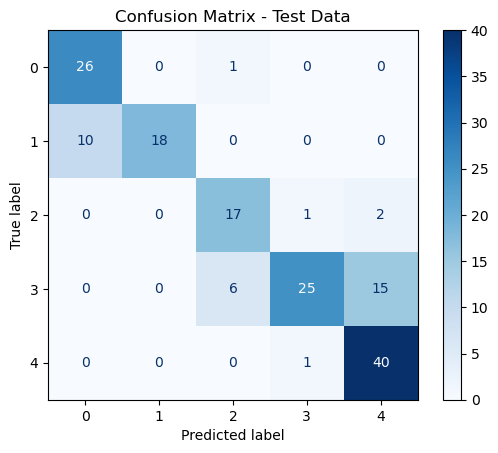

In [35]:
# Model evaluation function for test dataset
def evaluate_model_on_test(model, test_loader):
    model.eval()  # Set to evaluation mode
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for dynamic_graph in test_loader:
            # Process input features
            features, edge_indices, edge_weights, targets, batch, timestamps = dynamic_graph

            # Convert inputs to correct tensor formats
            edge_indices = convert_edges_to_long_tensor(edge_indices)
            edge_weights = convert_edge_weights_to_float_tensor(edge_weights)
            features = convert_features_to_float_tensor(features)
            targets = convert_targets_to_float_tensor(targets)

            dynamic_graph_batch = DynamicGraphTemporalSignalBatch(
                edge_indices=edge_indices,
                edge_weights=edge_weights,
                features=features,
                targets=targets,
                batches=batch,
                timestamps=timestamps
            )
            
            # Compute predictions
            out = out = model(features[1], edge_indices[1], edge_weights[1])
            predictions = out.argmax(dim=1)

            # Store labels and predictions
            all_preds.extend(predictions)
            all_labels.extend(targets[1])

    return np.array(all_preds), np.array(all_labels)

# Get predictions for test data
test_preds, test_labels = evaluate_model_on_test(model, test_loader)

# Compute confusion matrix
conf_matrix = confusion_matrix(test_labels, test_preds)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot(cmap=plt.cm.Blues)

plt.title("Confusion Matrix - Test Data")
plt.show()

In [36]:
# Convert tensors to NumPy arrays (if needed)
test_labels_np = np.array(test_labels)
test_preds_np = np.array(test_preds)

# Compute classification metrics
test_f1 = f1_score(test_labels_np, test_preds_np, average='weighted')
test_recall = recall_score(test_labels_np, test_preds_np, average='weighted')
test_accuracy = accuracy_score(test_labels_np, test_preds_np)
test_precision = precision_score(test_labels_np, test_preds_np, average='weighted')

# Print results
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test F1 Score: {test_f1:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")

Test Accuracy: 0.7778
Test F1 Score: 0.7693
Test Precision: 0.8212
Test Recall: 0.7778


In [37]:
# Ensure test labels and predictions are in NumPy format
test_labels_np = np.array(test_labels)
test_preds_np = np.array(test_preds)

# Generate classification report
report = classification_report(test_labels_np, test_preds_np)

# Print results
print("Classification Report:\n")
print(report)

Classification Report:

              precision    recall  f1-score   support

         0.0       0.72      0.96      0.83        27
         1.0       1.00      0.64      0.78        28
         2.0       0.71      0.85      0.77        20
         3.0       0.93      0.54      0.68        46
         4.0       0.70      0.98      0.82        41

    accuracy                           0.78       162
   macro avg       0.81      0.79      0.78       162
weighted avg       0.82      0.78      0.77       162



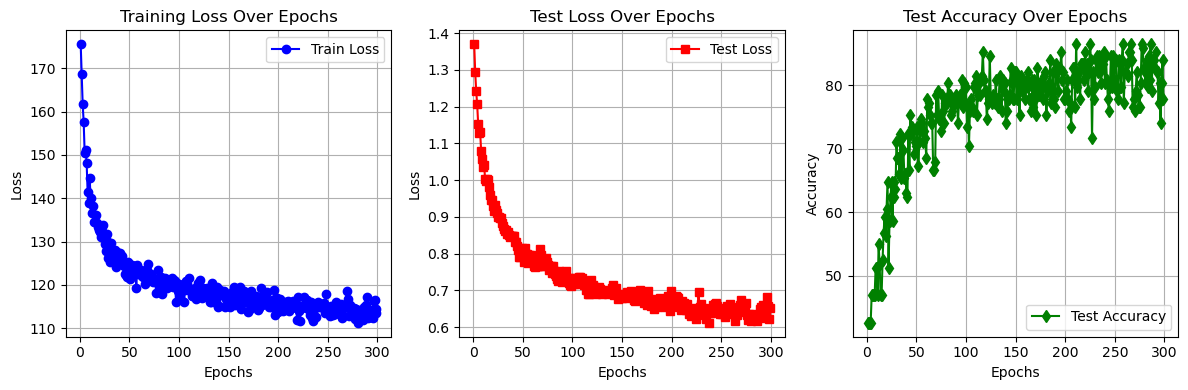

In [34]:
plt.figure(figsize=(12, 4))

# Train Loss Plot
plt.subplot(1, 3, 1)
plt.plot(PerformanceMatrices['Epoch'], PerformanceMatrices['Train Loss'], marker='o', linestyle='-', color='blue', label="Train Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid()

# Test Loss Plot
plt.subplot(1, 3, 2)
plt.plot(PerformanceMatrices['Epoch'], PerformanceMatrices['Test Loss'], marker='s', linestyle='-', color='red', label="Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Test Loss Over Epochs")
plt.legend()
plt.grid()

# Test Accuracy Plot
plt.subplot(1, 3, 3)
plt.plot(PerformanceMatrices['Epoch'], PerformanceMatrices['Test Accuracy'], marker='d', linestyle='-', color='green', label="Test Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Test Accuracy Over Epochs")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()
